<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana12/RegresionLinealPesos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
import numpy as np
import matplotlib.pyplot as plt

In [108]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [109]:
import os
os.chdir('/content/drive/MyDrive/ColabNotebooks/Cursos/MetodosComputacionales2026')

In [99]:
N = 5
x = np.linspace(0, 10, N)
b_real = 2.0
m_real = 1.8

sigma_y = 0.2 + 0.2*x

y_real = b_real + m_real * x
y = y_real + np.random.normal(0, sigma_y, N)

In [110]:
data = np.column_stack((x,y,sigma_y))
np.savetxt('data_weightedMC.csv', data, delimiter=',', header='x,y,sigma_y')

<ErrorbarContainer object of 3 artists>

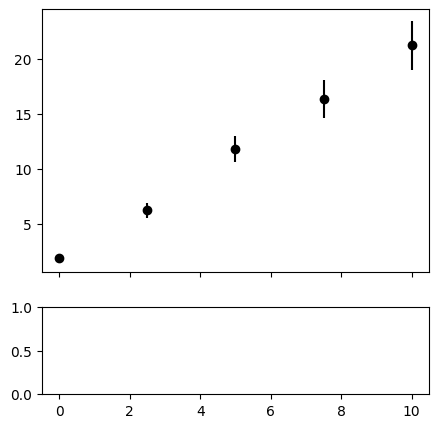

In [111]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')

In [112]:
# Programar minimos cuadrados ponderados
X = np.column_stack((np.ones(N),x))
X

array([[ 1. ,  0. ],
       [ 1. ,  2.5],
       [ 1. ,  5. ],
       [ 1. ,  7.5],
       [ 1. , 10. ]])

In [113]:
w = 1/sigma_y**2
w

array([25.        ,  2.04081633,  0.69444444,  0.34602076,  0.20661157])

In [114]:
# Ecuaciones de minimos cuadrados
A = X.T @ (w[:,None]*X)
B = X.T @ (w*y)

In [115]:
A

array([[28.2878931 , 13.23553445],
       [13.23553445, 70.241038  ]])

In [116]:
B

array([ 78.59709563, 158.97821665])

In [117]:
beta_hat = np.linalg.solve(A,B)
beta_hat

array([1.88574663, 1.90799219])

In [118]:
b,m = beta_hat
_x = np.linspace(0,10,100)
_y = b + m*_x

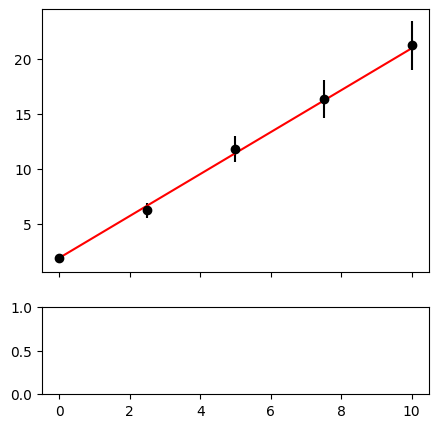

In [119]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')
ax1.plot(_x,_y,color='r')

In [120]:
A

array([[28.2878931 , 13.23553445],
       [13.23553445, 70.241038  ]])

In [121]:
# Queremos calcular el error en los modelos
C_beta = np.linalg.inv(A)
C_beta

array([[ 0.03876883, -0.00730522],
       [-0.00730522,  0.01561322]])

In [122]:
error_b, error_m = np.sqrt( np.diag(C_beta) )

In [123]:
print(b,error_b)

1.8857466349911727 0.19689801561786308


In [124]:
print(m,error_m)

1.9079921926550523 0.12495285394401097


In [125]:
y_fit = X @ beta_hat
residuos = y - y_fit
residuos_norm  = (y - y_fit)/sigma_y

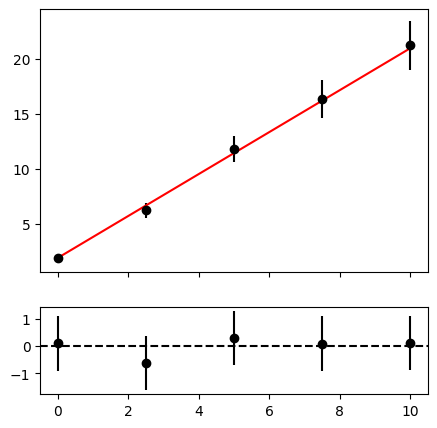

In [126]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')
ax1.plot(_x,_y,color='r')
ax2.errorbar(x, residuos_norm, yerr=1, fmt='o', color='k')
ax2.axhline(0, color='k', linestyle='--')